In [ ]:
# link https://clck.su/XYGEF
# link GasDynamic https://clck.su/ILpMg

<img src="https://drive.google.com/uc?export=download&id=1T85s_XRor61S-CEoYZusZsoai9x8LVLq" width="700"/>

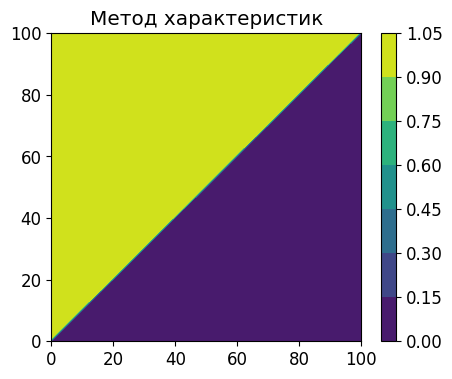

In [ ]:
import numpy as np; import matplotlib.pyplot as plt;
L=1; T=1.0; J=100; N=100; mu1=1; mu2=0;
tau=T/J; h=L/N;
u=np.zeros((J+1, N+1)); x=np.linspace(0, L, N+1); t=np.linspace(0, T, J+1)
r=1.0; v=tau/h
u[0,:]=0;
for j in range(J):
    u[j+1][N]=mu2
    for i in range(0, N+1): u[j+1][i]=u[j][i-1]
    u[j+1][0]=mu1

# Визуализация решения
plt.figure(figsize=(5, 4))
im = plt.contourf(u)
plt.colorbar(im)
plt.title("Метод характеристик")
plt.show()


In [ ]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display
import matplotlib.pyplot as plt

def animate(u, x, t, file="result.gif", fps=10):
    fig, ax = plt.subplots(); line, = ax.plot([], []); ax.grid(True)
    ax.set(xlim=(x.min(), x.max()), ylim=(1.1*u.min(), 1.1*u.max()))
    txt = ax.text(.8, .9, '', transform=ax.transAxes)
    skip = max(1, (len(t) - 1) // 50)
    def update(k):
        i = k * skip; line.set_data(x, u[i]); txt.set_text(f't={t[i]:.2f}')
        return line, txt

    FuncAnimation(fig, update, frames=(len(t)-1)//skip,
                  blit=True).save(file, writer=PillowWriter(fps=fps))
    plt.close(fig); display(Image(filename=file))

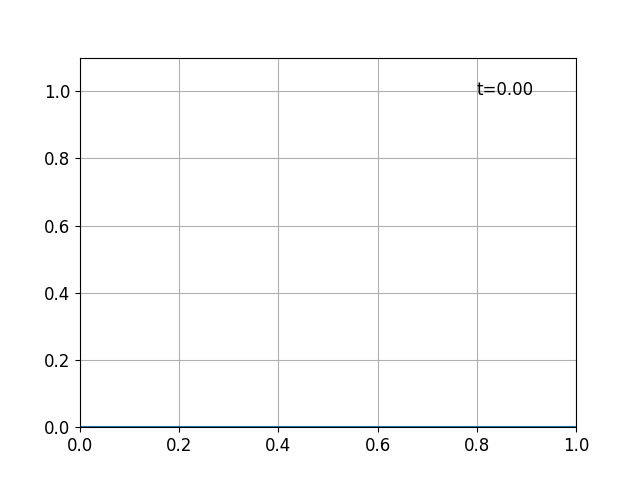

In [ ]:
animate(u, x, t)

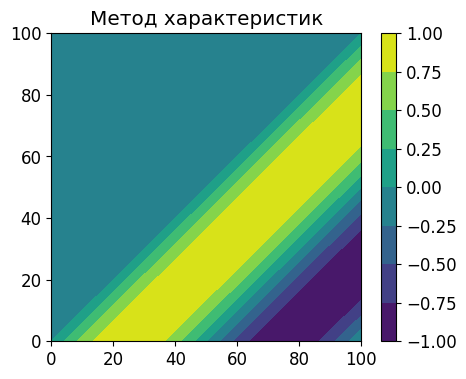

In [ ]:
import numpy as np; import matplotlib.pyplot as plt;
L=1; T=1.0; J=100; N=100; mu1=0; mu2=0;
tau=T/J; h=L/N;
u2=np.zeros((J+1, N+1)); x=np.linspace(0, L, N+1); t=np.linspace(0, T, J+1)
r=1.0; v=tau/h
u2[0,:]=np.sin(2*np.pi*x);
for j in range(J):
    u2[j+1][N]=mu2
    for i in range(0, N+1): u2[j+1][i]=u2[j][i-1]
    u2[j+1][0]=mu1

# Визуализация решения
plt.figure(figsize=(5, 4))
im = plt.contourf(u2)
plt.colorbar(im)
plt.title("Метод характеристик")
plt.show()


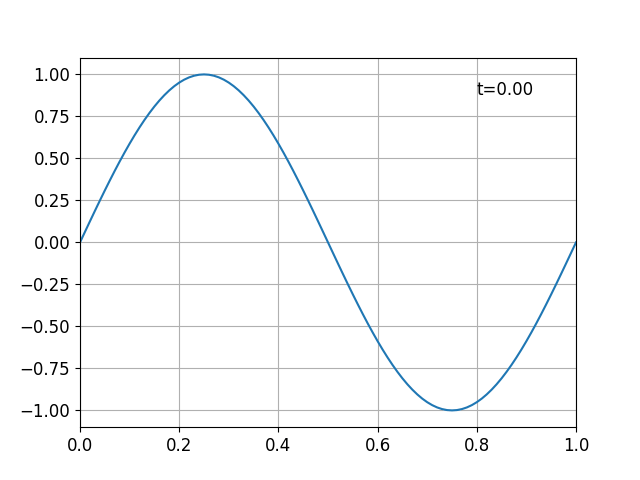

In [ ]:
animate(u2, x, t)

## Задача Коши для уравнения переноса

Найти $u(x,t)$ в $\Omega_T=(0,l)\times(0,T]$:

$$
\frac{\partial u}{\partial t}
+v(x,t)\frac{\partial u}{\partial x}=0,
\qquad v(x,t)>0.
$$

$$
u(0,t)=\mu(t),\qquad
u(x,0)=u_0(x).
$$

### Разностная схема

Сетки:

$$
x_i=ih,\quad h=\frac{l}{N},\qquad
t_j=j\tau,\quad \tau=\frac{T}{J},
$$

$$
y_i^j\approx u(x_i,t_j),\qquad v_i^j=v(x_i,t_j).
$$

Начальное и граничное условия:

$$
y_i^0=u_0(x_i),\qquad
y_0^j=\mu(t_j).
$$

Для $i=1,\ldots,N$:

$$
\frac{y_i^j-y_i^{j-1}}{\tau}
+v_i^j\frac{y_i^{j-1}-y_{i-1}^{j-1}}{h}=0.
$$

Обозначая число Куранта

$$
r_i^j=\frac{\tau v_i^j}{h},
$$

получаем

$$
\boxed{
y_i^j=(1-r_i^j)y_i^{j-1}+r_i^j y_{i-1}^{j-1}
}.
$$

Условие устойчивости (CFL):

$$
\boxed{
0\le r_i^j\le1
}
\qquad\Longleftrightarrow\qquad
\tau\le\frac{h}{\max v(x,t)}.
$$

При $r=1$:

$$
\boxed{y_i^j=y_{i-1}^{j-1}},
\qquad
\tau=\frac{h}{v}.
$$

r = 1.0


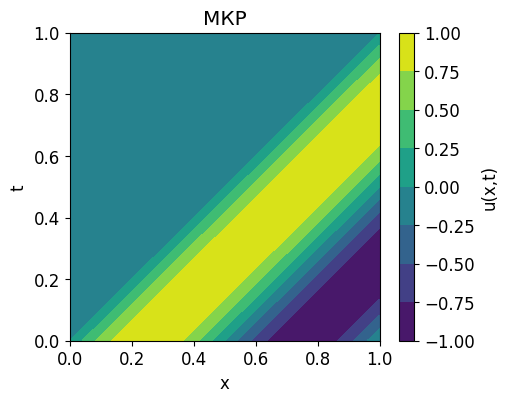

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

L=1.0; T=1.0; N=100; J=100; tau=T/J; h=L/N
a = 1.0; mu1 = 0
x = np.linspace(0, L, N+1); t = np.linspace(0, T, J+1)

r = a*tau/h
u3 = np.zeros((J+1, N+1))
# Начальное условие
u3[0, :] = np.sin(2*np.pi*x)
# Метод конечных разностей
for j in range(J):
    u3[j+1, 0] = mu1
    for i in range(1, N+1):
        u3[j+1, i] = u3[j, i] - r*(u3[j, i] - u3[j, i-1])
print(f"r = {r}")
# Визуализация
X, Tm = np.meshgrid(x, t)

plt.figure(figsize=(5, 4))
im = plt.contourf(X, Tm, u3)
plt.colorbar(im, label='u(x,t)')
plt.xlabel('x')
plt.ylabel('t')
plt.title('МКР')
plt.show()

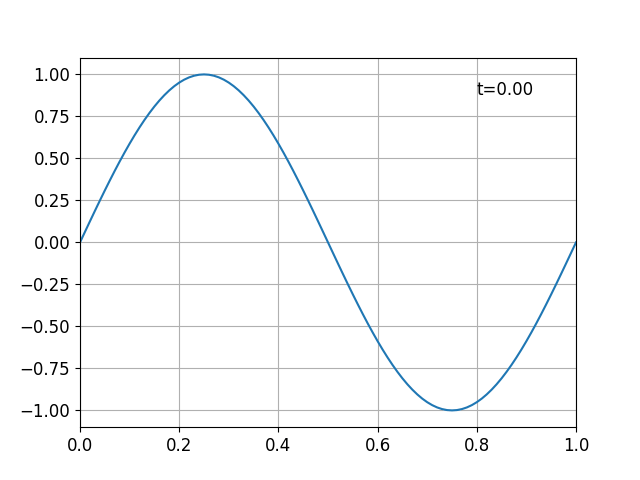

In [ ]:
animate(u3, x, t)

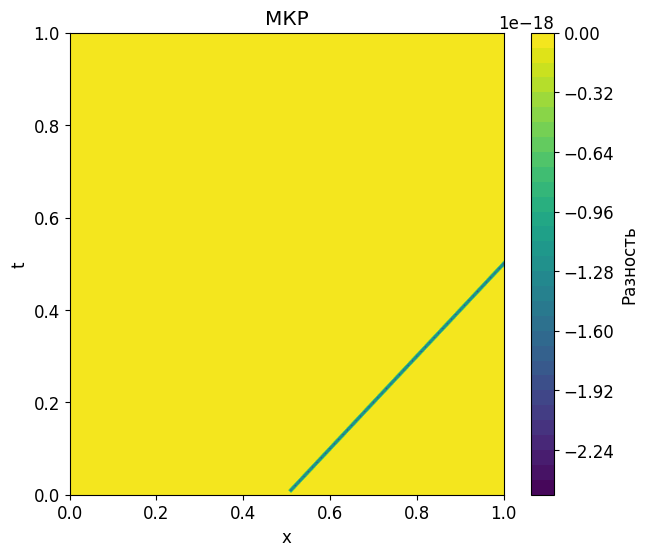

In [ ]:
X, Tm = np.meshgrid(x, t)

plt.figure(figsize=(7, 6))
im = plt.contourf(X, Tm, u2-u3, levels=30)
plt.colorbar(im, label='Разность')
plt.xlabel('x')
plt.ylabel('t')
plt.title('МКР')
plt.show()

In [ ]:
print(np.mean(u2-u3))

-1.1937115751371385e-20


## Задача Коши для уравнения Хопфа

Найти $u(x,t)$ в $\Omega_T=(0,l)\times(0,T]$:

$$
\frac{\partial u}{\partial t}
+u\frac{\partial u}{\partial x}=0,
\qquad u(x,t)>0.
$$

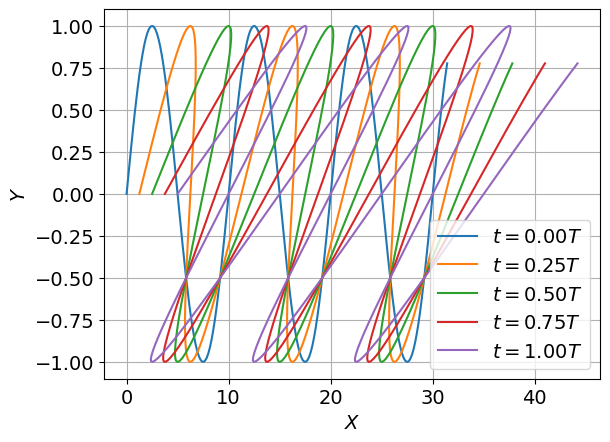

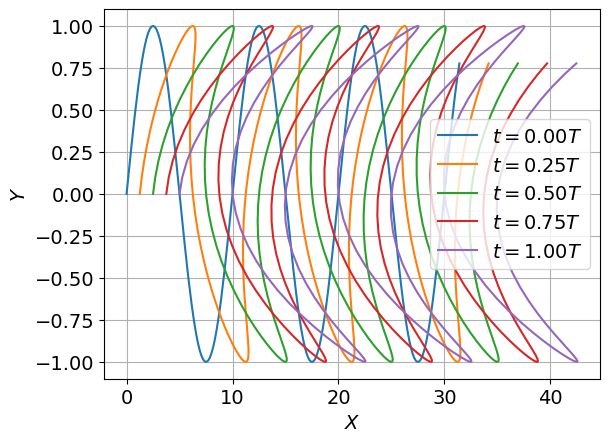

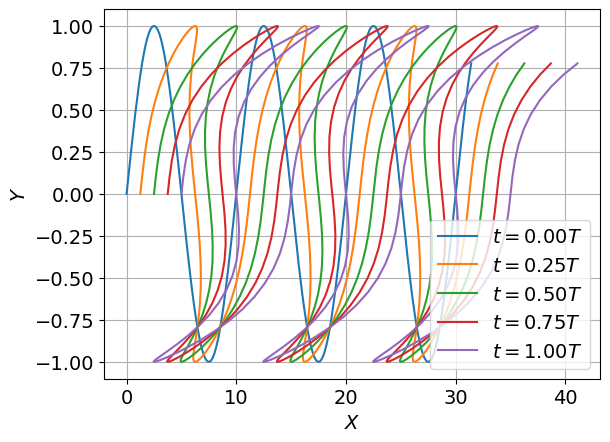

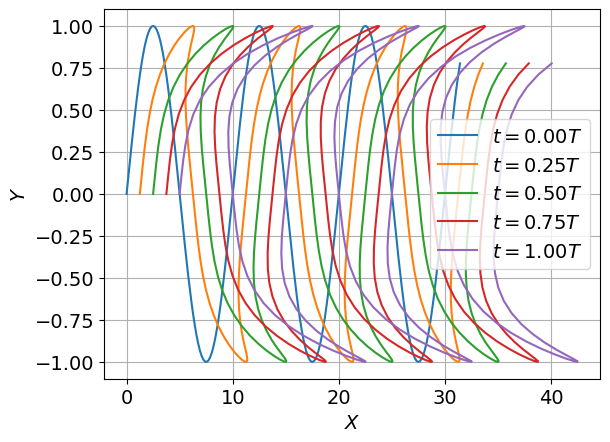

In [ ]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams.update({'font.size': 14})
def U0(x): return np.sin(2*np.pi*x/10.)
N = 200; pi = np.pi; l = 10. * pi; l1 = 0.; h = l / N; t = 10.; J = 4; K = 4
x0 = np.zeros(N + 1, 'float'); y = np.zeros(N + 1, 'float')
x = np.linspace(l1, l, N+1); k = np.arange(0, K + 1)

for j in range(1, J + 1):
    y = U0(x)
    x0 = x[:, None] + (0.5 + y[:, None]**j) * k[None, :] * t / K
    plt.figure(); plt.grid(True); plt.xlabel('$X$');plt.ylabel('$Y$')
    for n in range(K + 1):
        plt.plot(x0[:, n], y, label=f'$t={n/K:.2f}T$')
    plt.legend()
plt.show()

Energy error = 5.551e-15
min(rho) = 0.950366
min(p) = 1.000000


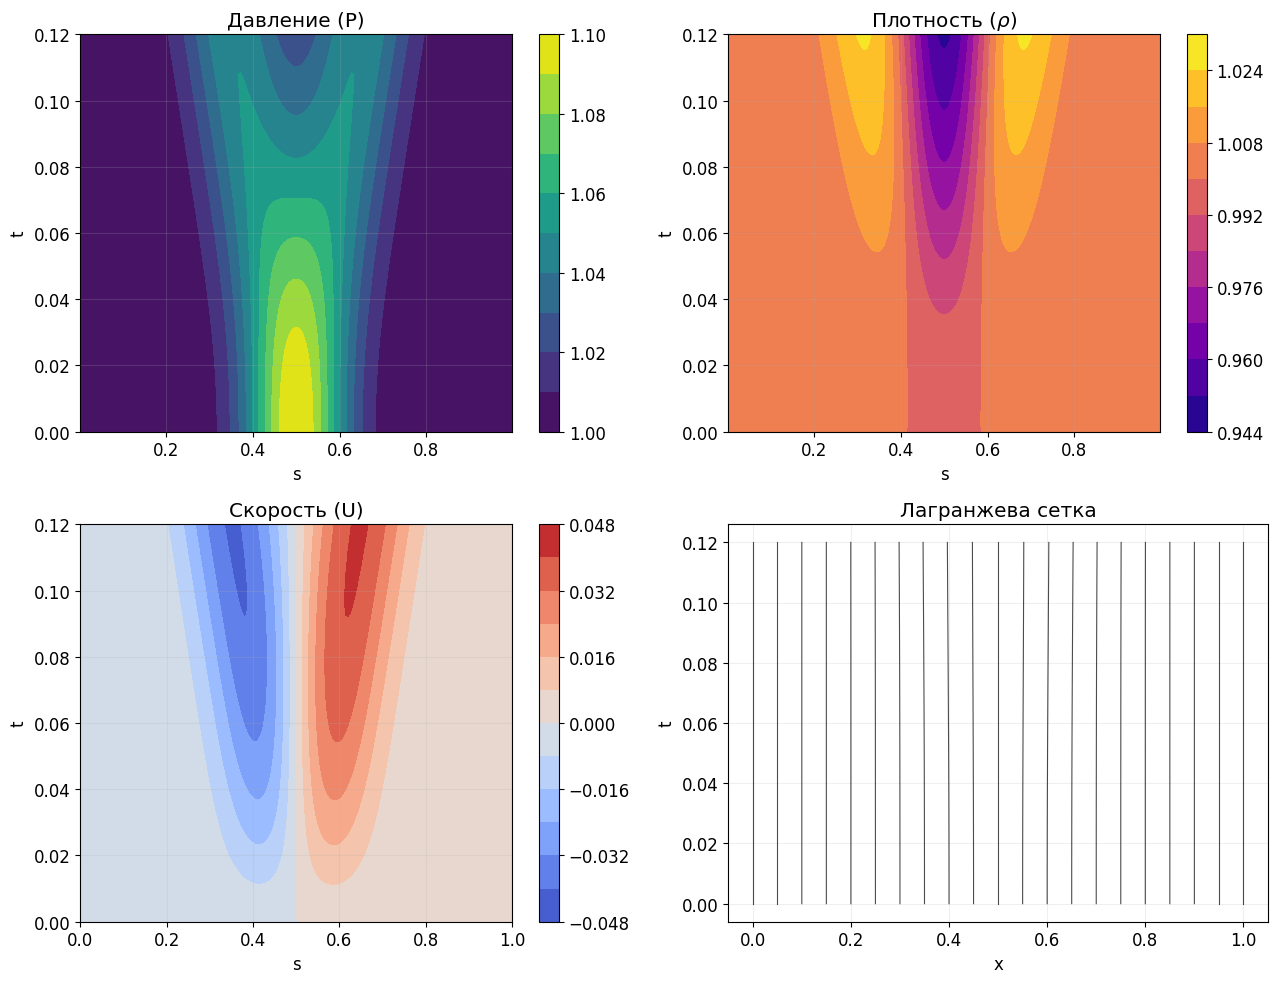

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 12})

# Параметры задачи
L, T, N, M = 1.0, 0.12, 200, 80
gamma = 1.4
h, tau = L/N, T/M

s = np.linspace(0, L, N+1)
sc = 0.5*(s[:-1] + s[1:])
t = np.linspace(0, T, M+1)

# Лагранжева сетка и искомые функции
X = np.zeros((M+1, N+1))
U = np.zeros((M+1, N+1))
V = np.zeros((M+1, N))
E = np.zeros((M+1, N))
P = np.zeros((M+1, N))

# Начальные условия
X[0] = s
V[0] = 1.0
P[0] = 1.0 + 0.1*np.exp(-((sc-0.5)/0.12)**2)
E[0] = P[0]*V[0]/(gamma-1)

# Метод прогонки
def progonka(a, b, c, d):
    n = len(b)
    alpha, beta = np.zeros(n-1), np.zeros(n)

    # Прямой ход
    alpha[0] = c[0] / b[0]
    beta[0] = d[0] / b[0]

    for i in range(1, n - 1):
        z = b[i] - a[i-1] * alpha[i-1]
        alpha[i] = c[i] / z
        beta[i] = (d[i] - a[i-1] * beta[i-1]) / z

    beta[-1] = (d[-1] - a[-1] * beta[-2]) / (b[-1] - a[-1] * alpha[-1])

    # Обратный ход
    y = np.zeros(n)
    y[-1] = beta[-1]
    for i in range(n - 2, -1, -1):
        y[i] = beta[i] - alpha[i] * y[i+1]

    return y


# Полностью консервативная МКР
mu = tau**2/(4*h**2)

for j in range(M):
    v = U[j].copy()

    # Метод Ньютона для нелинейной системы
    for k in range(20):
        # Приращение удельного объема
        dV = 0.5 * (tau / h) * (np.diff(v) + np.diff(U[j]))
        V1 = V[j] + dV

        # Знаменатель и числитель для нового давления (p1 = B / D)
        D = V[j] + 0.5 * (gamma + 1) * dV
        B = (gamma - 1) * (E[j] - 0.5 * P[j] * dV)

        if V1.min() <= 0 or D.min() <= 0 or B.min() <= 0:
            raise RuntimeError(f"Нефизическое состояние: j={j}")

        p1 = B / D

        # Производная давления dp/dv (упрощенная аналитическая форма)
        dp = -0.5 * ((gamma - 1) * P[j] + (gamma + 1) * p1) / D

        # Невязка уравнений движения
        F = v[1:-1] - U[j, 1:-1] + 0.5 * (tau / h) * np.diff(p1 + P[j])

        if np.max(np.abs(F)) < 1e-12:
            break

        # Коэффициенты трехдиагональной матрицы для прогонки
        a = mu * dp[1:-1]
        b = 1.0 - mu * (dp[:-1] + dp[1:])

        # Поправка метода Ньютона
        v[1:-1] += progonka(a, b, a, -F)
    else:
        raise RuntimeError(f"Нет сходимости Ньютона: j={j}")


    # Переход на новый временной слой
    U[j+1] = v
    X[j+1] = X[j] + 0.5*tau*(U[j] + U[j+1])
    V[j+1] = V1
    P[j+1] = p1
    E[j+1] = E[j] - 0.5*(P[j] + P[j+1])*dV


# Проверка сохранения энергии
rho = 1/V
H = h*np.sum(E + 0.25*(U[:, :-1]**2 + U[:, 1:]**2), axis=1)
err = np.abs(H/H[0] - 1)

print(f"Energy error = {err.max():.3e}")
print(f"min(rho) = {rho.min():.6f}")
print(f"min(p) = {P.min():.6f}")


# Визуализация решения
# --- Упрощенная 2D визуализация всех полей ---
fig, ax = plt.subplots(2, 2, figsize=(13, 10))

# 1. Давление P(s, t)
im00 = ax[0, 0].contourf(sc, t, P, levels=10, cmap='viridis')
fig.colorbar(im00, ax=ax[0, 0])
ax[0, 0].set(title='Давление (P)', xlabel='s', ylabel='t')

# 2. Плотность rho(s, t)
im01 = ax[0, 1].contourf(sc, t, rho, levels=10, cmap='plasma')
fig.colorbar(im01, ax=ax[0, 1])
ax[0, 1].set(title='Плотность ($\\rho$)', xlabel='s', ylabel='t')

# 3. Скорость U(s, t)
im10 = ax[1, 0].contourf(s, t, U, levels=10, cmap='coolwarm')
fig.colorbar(im10, ax=ax[1, 0])
ax[1, 0].set(title='Скорость (U)', xlabel='s', ylabel='t')

# 4. Движение лагранжевой сетки X(s, t)
for i in range(0, N+1, 10):
    ax[1, 1].plot(X[:, i], t, lw=0.8, color='black', alpha=0.7)
ax[1, 1].set(title='Лагранжева сетка', xlabel='x', ylabel='t')

# Настройка сеток для всех графиков
for a in ax.flat:
    a.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

Energy error = 2.220e-16
min(rho) = 0.643473
min(p) = 0.893396


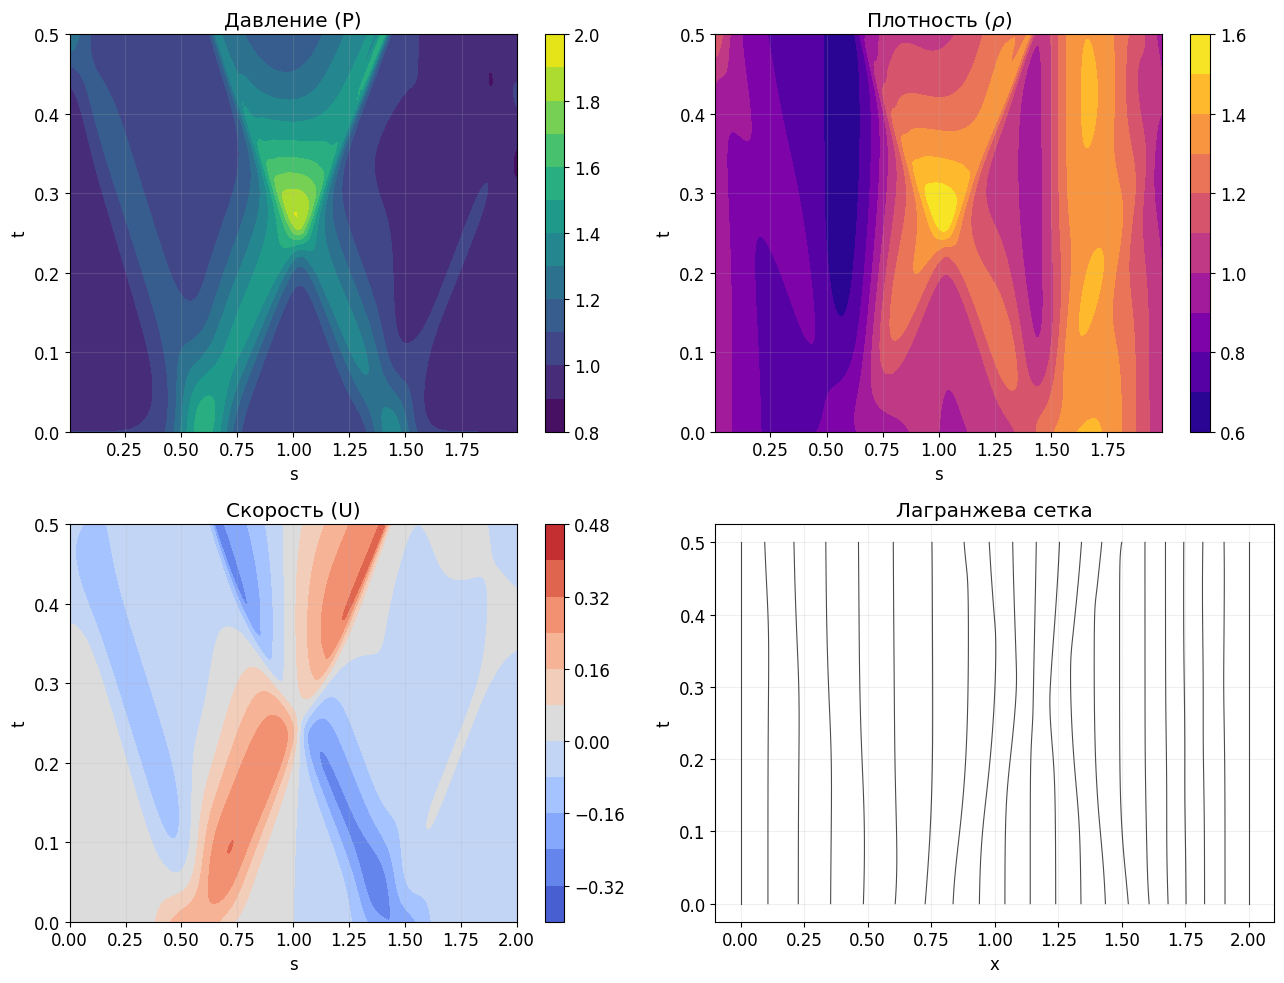

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 12})

# Параметры задачи
L, T, N, M = 2.0, 0.5, 200, 80
gamma = 1.4
h, tau = L/N, T/M

s = np.linspace(0, L, N+1)
sc = 0.5*(s[:-1] + s[1:])
t = np.linspace(0, T, M+1)

# Лагранжева сетка и искомые функции
X = np.zeros((M+1, N+1))
U = np.zeros((M+1, N+1))
V = np.zeros((M+1, N))
E = np.zeros((M+1, N))
P = np.zeros((M+1, N))

# Начальные условия
# X[0] = s
# V[0] = 1.0
# P[0] = 1.0 + np.sin(2*np.pi*sc)/L #+ #0.1*np.exp(-((sc-0.5)/0.12)**2)
# E[0] = P[0]*V[0]/(gamma-1)

V[0] = 1 + 0.22*np.sin(2*np.pi*sc/L) + 0.12*np.sin(4*np.pi*sc/L)

X[0, 0] = 0
X[0, 1:] = h*np.cumsum(V[0])

P[0] = (1
        + 0.55*np.exp(-((sc-0.30*L)/(0.065*L))**2)
        + 0.35*np.exp(-((sc-0.72*L)/(0.050*L))**2))

U[0] = 0.24*(np.exp(-((s-0.28*L)/(0.085*L))**2)
             - np.exp(-((s-0.72*L)/(0.085*L))**2))

U[0, 0] = U[0, -1] = 0
E[0] = P[0]*V[0]/(gamma-1)


# Метод прогонки
def progonka(a, b, c, d):
    n = len(b)
    alpha, beta = np.zeros(n-1), np.zeros(n)

    # Прямой ход
    alpha[0] = c[0] / b[0]
    beta[0] = d[0] / b[0]

    for i in range(1, n - 1):
        z = b[i] - a[i-1] * alpha[i-1]
        alpha[i] = c[i] / z
        beta[i] = (d[i] - a[i-1] * beta[i-1]) / z

    beta[-1] = (d[-1] - a[-1] * beta[-2]) / (b[-1] - a[-1] * alpha[-1])

    # Обратный ход
    y = np.zeros(n)
    y[-1] = beta[-1]
    for i in range(n - 2, -1, -1):
        y[i] = beta[i] - alpha[i] * y[i+1]

    return y


# Линеаризация Пикара + метод прогонки
mu = tau**2/(4*h**2)

for j in range(M):
    v = U[j].copy()

    for k in range(50):
        # 1. Линеаризация давления
        dV = tau/(2*h)*(np.diff(v) + np.diff(U[j]))
        D = V[j] + 0.5*(gamma+1)*dV
        K = gamma*P[j]/D

        # 2. Трехдиагональная система
        a = -mu*K[1:-1]
        b = 1 + mu*(K[:-1] + K[1:])
        F = (U[j, 1:-1] - tau/h*np.diff(P[j])
             + mu*np.diff(K*np.diff(U[j])))

        v1 = v.copy()
        v1[1:-1] = progonka(a, b, a, F)

        # 3. Восстановление термодинамических величин
        dV1 = tau/(2*h)*(np.diff(v1) + np.diff(U[j]))
        V1 = V[j] + dV1

        D1 = V[j] + 0.5*(gamma+1)*dV1
        B1 = (gamma-1)*(E[j] - 0.5*P[j]*dV1)

        if min(V1.min(), D1.min(), B1.min()) <= 0:
            raise RuntimeError(f"Нефизическое состояние: j={j}")

        p1 = B1/D1

        # 4. Критерий сходимости
        R = (v1[1:-1] - U[j, 1:-1]
             + tau/(2*h)*np.diff(P[j] + p1))

        v = v1

        if np.max(np.abs(R)) < 1e-12:
            break
    else:
        raise RuntimeError(f"Нет сходимости Пикара: j={j}")

    # 5. Переход на следующий временной слой
    U[j+1] = v
    V[j+1] = V1
    P[j+1] = p1
    E[j+1] = E[j] - 0.5*(P[j] + p1)*dV1
    X[j+1] = X[j] + 0.5*tau*(U[j] + v)


# Проверка сохранения энергии
rho = 1/V
H = h*np.sum(E + 0.25*(U[:, :-1]**2 + U[:, 1:]**2), axis=1)
err = np.abs(H/H[0] - 1)

print(f"Energy error = {err.max():.3e}")
print(f"min(rho) = {rho.min():.6f}")
print(f"min(p) = {P.min():.6f}")


# Визуализация решения
# --- Упрощенная 2D визуализация всех полей ---
fig, ax = plt.subplots(2, 2, figsize=(13, 10))

# 1. Давление P(s, t)
im00 = ax[0, 0].contourf(sc, t, P, levels=10, cmap='viridis')
fig.colorbar(im00, ax=ax[0, 0])
ax[0, 0].set(title='Давление (P)', xlabel='s', ylabel='t')

# 2. Плотность rho(s, t)
im01 = ax[0, 1].contourf(sc, t, rho, levels=10, cmap='plasma')
fig.colorbar(im01, ax=ax[0, 1])
ax[0, 1].set(title='Плотность ($\\rho$)', xlabel='s', ylabel='t')

# 3. Скорость U(s, t)
im10 = ax[1, 0].contourf(s, t, U, levels=10, cmap='coolwarm')
fig.colorbar(im10, ax=ax[1, 0])
ax[1, 0].set(title='Скорость (U)', xlabel='s', ylabel='t')

# 4. Движение лагранжевой сетки X(s, t)
for i in range(0, N+1, 10):
    ax[1, 1].plot(X[:, i], t, lw=0.8, color='black', alpha=0.7)
ax[1, 1].set(title='Лагранжева сетка', xlabel='x', ylabel='t')

# Настройка сеток для всех графиков
for a in ax.flat:
    a.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

def animateGasDynamic(vel, rho, pres, x, sc, t, file="result.gif", fps=20):
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.5), sharex=True)
    fields = [vel, rho, pres]
    titles = ['Скорость $u$', 'Плотность $\\rho$', 'Давление $p$']

    xc = 0.5*(x[:, :-1] + x[:, 1:]) if x.ndim == 2 else sc
    lines = []

    for a, y, title in zip(ax, fields, titles):
        line, = a.plot([], [], lw=2)
        lines.append(line)

        dy = max(0.05*(y.max()-y.min()), 1e-6)
        a.set(xlim=(x.min(), x.max()),
              ylim=(y.min()-dy, y.max()+dy),
              xlabel='$x$', title=title)
        a.grid(alpha=0.3)

    txt = ax[0].text(0.05, 0.9, '', transform=ax[0].transAxes)
    skip = max(1, (len(t)-1)//100)
    frames = np.unique(np.r_[np.arange(0, len(t), skip), len(t)-1])

    def update(j):
        xn = x[j] if x.ndim == 2 else x
        cn = xc[j] if xc.ndim == 2 else xc

        for line, xx, y in zip(lines, [xn, cn, cn], fields):
            line.set_data(xx, y[j])

        txt.set_text(f'$t={t[j]:.3f}$')
        return *lines, txt

    ani = FuncAnimation(fig, update, frames=frames, blit=True)
    ani.save(file, writer=PillowWriter(fps=fps))
    plt.close(fig)
    display(Image(filename=file))

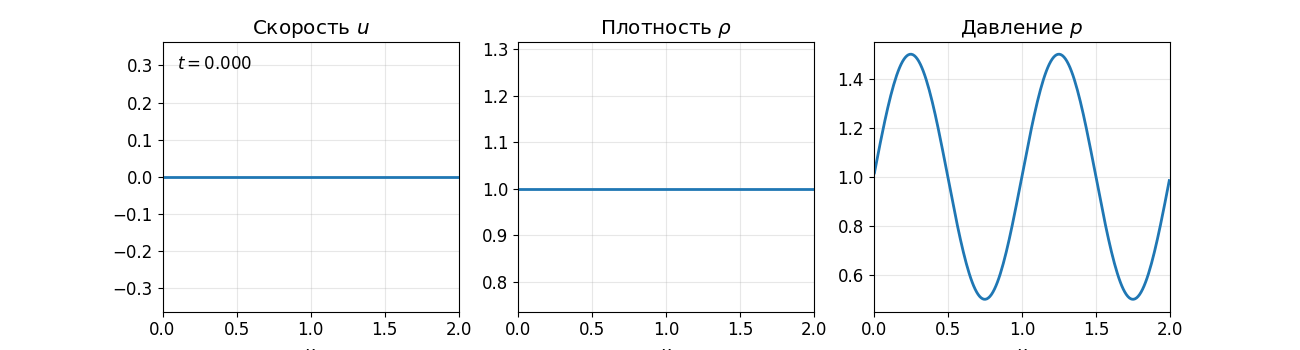

In [ ]:
animateGasDynamic(U, rho, P, X, sc, t, fps=20)

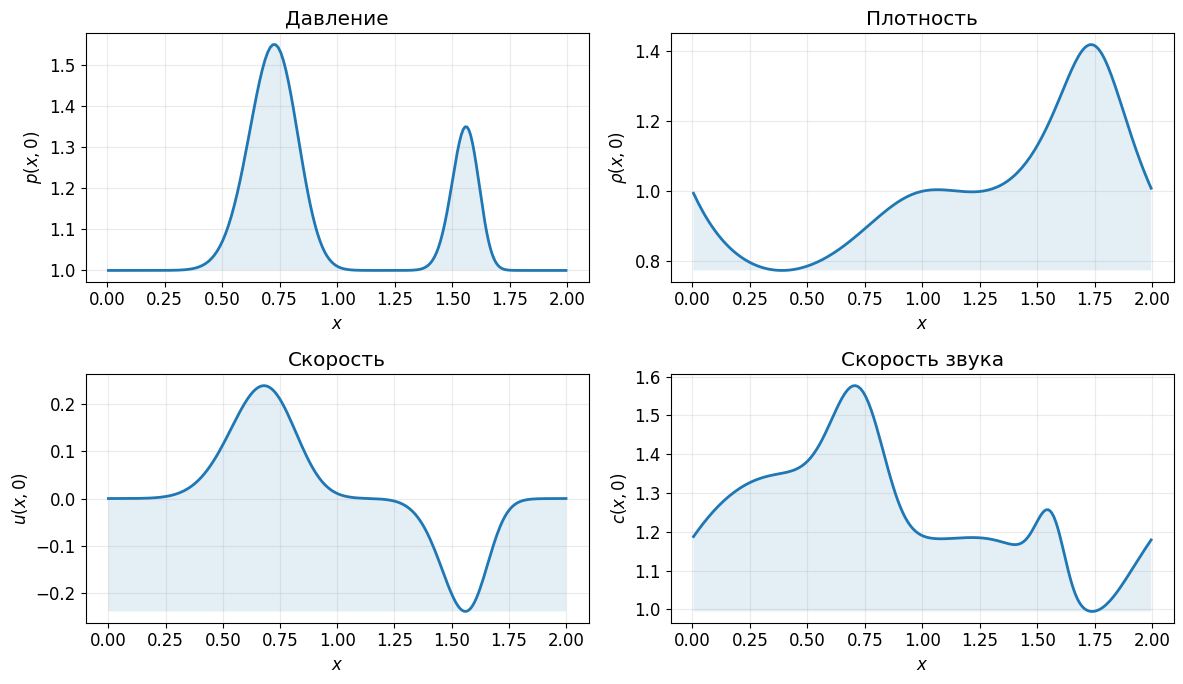

In [ ]:

rho0 = 1/V[0]
c0 = np.sqrt(gamma*P[0]*V[0])
xc = 0.5*(X[0, :-1] + X[0, 1:])

fig, ax = plt.subplots(2, 2, figsize=(12, 7))

data = [
    (xc, P[0], 'Давление', '$p(x,0)$'),
    (xc, rho0, 'Плотность', r'$\rho(x,0)$'),
    (X[0], U[0], 'Скорость', '$u(x,0)$'),
    (xc, c0, 'Скорость звука', '$c(x,0)$')
]

for a, (xx, yy, title, ylabel) in zip(ax.flat, data):
    a.plot(xx, yy, lw=2)
    a.fill_between(xx, yy.min(), yy, alpha=0.12)
    a.set(title=title, xlabel='$x$', ylabel=ylabel)
    a.grid(alpha=0.25)

plt.tight_layout()
plt.show()


In [ ]:
try:
    import dolfin
except ImportError:
    !wget "https://fem-on-colab.github.io/releases/fenics-install-release-real.sh" -O "/tmp/fenics-install.sh" && bash "/tmp/fenics-install.sh"
    import dolfin

ALE-DG0:   0%|          | 0.0000/0.8000 [00:00<?, ]

Сохранение GIF:   0%|          | 0/210 [00:00<?, ?it/s]

IndexError: list index out of range

Error in callback <function _draw_all_if_interactive at 0x7d89d01ae520> (for post_execute):


AttributeError: 'PolyCollection' object has no attribute 'set_triangulation'

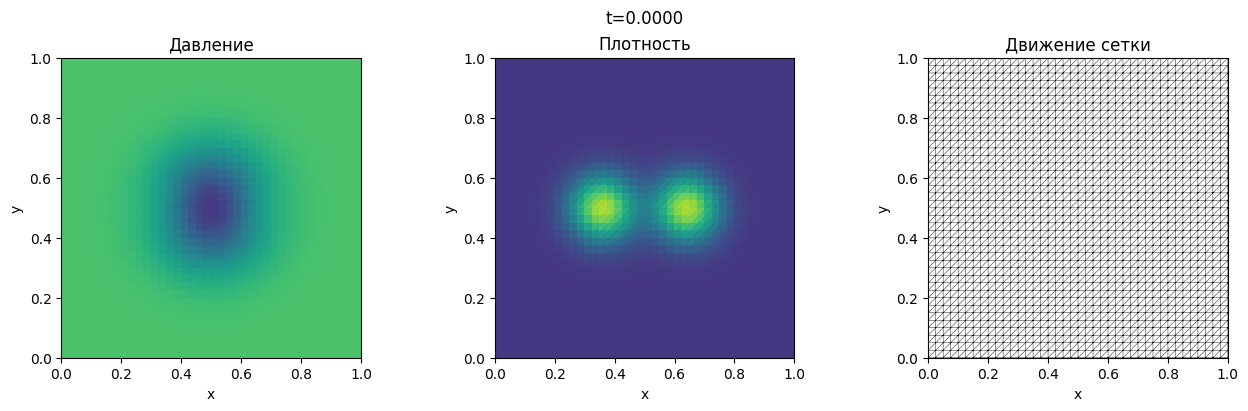

In [ ]:
"""DOLFIN 2019: 2D Euler, строго консервативная схема ALE-DG0.
Запуск: python3 gas_ale_dolfin2019.py
"""
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib.animation import FuncAnimation, PillowWriter
from dolfin import UnitSquareMesh, MPI
from tqdm.auto import tqdm

N, T, gamma, CFL = 40, 0.8, 1.4, 0.28
move_factor, save_every = 0.35, 8


def area(x, tri):
    d = x[tri[:, 1]] - x[tri[:, 0]]
    e = x[tri[:, 2]] - x[tri[:, 0]]
    return 0.5 * (d[:, 0] * e[:, 1] - d[:, 1] * e[:, 0])


def pressure(q):
    return (gamma - 1) * (q[:, 3] - 0.5 * np.sum(q[:, 1:3]**2, axis=1) / q[:, 0])


def edge_normals(x, edges):
    """Внешняя единичная нормаль к ячейке left и длина ребра."""
    d = x[edges[:, 1]] - x[edges[:, 0]]
    N_vec = np.column_stack((d[:, 1], -d[:, 0]))
    L = np.linalg.norm(N_vec, axis=1)
    return N_vec / L[:, None], L


def flux(q, n, wn):
    rho, mx, my, E = q.T
    un = (mx * n[:, 0] + my * n[:, 1]) / rho
    p = pressure(q)
    f = np.column_stack((
        rho * un,
        mx * un + p * n[:, 0],
        my * un + p * n[:, 1],
        (E + p) * un,
    )) - wn[:, None] * q
    return f, np.abs(un - wn) + np.sqrt(gamma * p / rho)


def rusanov(q, n, wn, left, right, wall):
    ql = q[left]
    qr = q[np.maximum(right, 0)].copy()
    # На неподвижной стенке отражаем нормальный импульс
    qr[wall, 1:3] -= 2 * np.sum(ql[wall, 1:3] * n[wall], axis=1)[:, None] * n[wall]

    fl, sl = flux(ql, n, wn)
    fr, sr = flux(qr, n, wn)
    speed = np.maximum(sl, sr)
    fn = 0.5 * (fl + fr - speed[:, None] * (qr - ql))
    fn[wall, 0] = 0.0  # Точное отсутствие потока массы через границу
    fn[wall, 3] = 0.0  # Точное отсутствие потока энергии через границу
    return fn, speed


# --- 1. Сетка и ориентированные рёбра ---
mesh = UnitSquareMesh(N, N)
if MPI.size(mesh.mpi_comm()) != 1:
    raise RuntimeError("Нужен последовательный запуск: 1 MPI-процесс")

coords = mesh.coordinates().copy().reshape(-1, 2)
tri = mesh.cells().copy().astype(np.int32)

# Приводим все треугольники к положительному обходу (против часовой стрелки)
flip = area(coords, tri) < 0
tri[flip, 1:] = tri[flip, 1:][:, ::-1]

# Строим ориентированные рёбра: для ячейки left ребро всегда идёт против часовой стрелки
edge_map, edges, left, right = {}, [], [], []
for c, (v0, v1, v2) in enumerate(tri):
    for i, j in ((int(v0), int(v1)), (int(v1), int(v2)), (int(v2), int(v0))):
        if (j, i) in edge_map:
            right[edge_map[j, i]] = c
        else:
            edge_map[i, j] = len(edges)
            edges.append((i, j))
            left.append(c)
            right.append(-1)

edges = np.asarray(edges, dtype=np.int32)
left, right = np.asarray(left, dtype=np.int32), np.asarray(right, dtype=np.int32)
interior = right >= 0
wall = ~interior
fixed = np.unique(edges[wall])

# --- 2. Начальное состояние ---
a0 = area(coords, tri)
# Спиральный вихрь с центробежным балансом давления
xx, yy = np.mean(coords[tri], axis=1).T
dx, dy = xx - 0.5, yy - 0.5
r2 = dx**2 + dy**2

# Угловая скорость вращения (затухает к границам)
omega = 9.5 * np.exp(-r2 / 0.045)
u = -omega * dy
v =  omega * dx

# Два эксцентричных плотных облака, которые закручиваются в спираль
blobs = (np.exp(-((xx - 0.36)**2 + (yy - 0.50)**2) / 0.012) +
         np.exp(-((xx - 0.64)**2 + (yy - 0.50)**2) / 0.012))
rho = 0.85 + 1.15 * blobs

# Пониженное давление в центре удерживает вихрь от разлёта
p = 1.75 - 0.95 * np.exp(-r2 / 0.035) + 0.15 * blobs

q = np.column_stack((rho, rho * u, rho * v, p / (gamma - 1) + 0.5 * rho * (u**2 + v**2)))

# U = A * q — интегральные консервативные величины в ячейках (масса, импульс, энергия)
U = a0[:, None] * q
mass0, energy0 = np.sum(U[:, 0]), np.sum(U[:, 3])
snaps, history, time, step = [(coords.copy(), q.copy(), 0.0)], [], 0.0, 0

# --- 3. Основной цикл по времени с прогресс-баром ---
with tqdm(total=T, desc="ALE-DG0", unit="s",
          bar_format="{l_bar}{bar}| {n:.4f}/{total:.4f} [{elapsed}<{remaining}, {postfix}]") as pbar:
    while time < T - 1e-12:
        a = area(coords, tri)
        q = U / a[:, None]

        # Сглаженная скорость узлов сетки (граница неподвижна)
        w = np.zeros_like(coords)
        weights = np.zeros(len(coords))
        np.add.at(w, tri.ravel(), np.repeat(U[:, 1:3] / q[:, :1], 3, axis=0))
        np.add.at(weights, tri.ravel(), np.repeat(a, 3))
        w *= move_factor / weights[:, None]
        w[fixed] = 0.0

        # Выбор шага dt по условию Куранта (CFL)
        n, L = edge_normals(coords, edges)
        wn = np.sum(0.5 * (w[edges[:, 0]] + w[edges[:, 1]]) * n, axis=1)
        _, speed = rusanov(q, n, wn, left, right, wall)
        denom = np.zeros(len(tri))
        np.add.at(denom, left, speed * L)
        np.add.at(denom, right[interior], (speed * L)[interior])
        dt = min(T - time, CFL * np.min(a / denom))
        while np.any(area(coords + dt * w, tri) < 0.35 * a0):
            dt *= 0.5

        # Геометрия на полушаге по времени (точный GCL)
        n, L = edge_normals(coords + 0.5 * dt * w, edges)
        wn = np.sum(0.5 * (w[edges[:, 0]] + w[edges[:, 1]]) * n, axis=1)
        fn, _ = rusanov(q, n, wn, left, right, wall)

        # Строго консервативное обновление интегральных величин U
        dU = dt * L[:, None] * fn
        np.subtract.at(U, left, dU)
        np.add.at(U, right[interior], dU[interior])

        # Движение сетки (универсально для DOLFIN 2019 и DOLFINx)
        coords += dt * w
        if hasattr(mesh, "coordinates"):
            mesh.coordinates()[:] = coords          # DOLFIN 2019
        else:
            domain.geometry.x[:, :2] = coords       # DOLFINx

        a_new = area(coords, tri)
        q = U / a_new[:, None]

        time += dt
        step += 1
        min_ratio = np.min(a_new / a0)
        history.append((
            time,
            np.sum(U[:, 0]) / mass0 - 1.0,
            np.sum(U[:, 3]) / energy0 - 1.0,
            min_ratio,
        ))
        if step % save_every == 0 or time >= T - 1e-12:
            snaps.append((coords.copy(), q.copy(), time))

        # Обновление прогресс-бара на величину шага dt
        pbar.update(dt)
        pbar.set_postfix(step=step, dt=f"{dt:.2e}", min_A=f"{min_ratio:.2f}")

# --- 4. Графики и анимация ---
history = np.asarray(history)
fig, ax = plt.subplots(2, 2, figsize=(11, 9), constrained_layout=True)
triang = mtri.Triangulation(coords[:, 0], coords[:, 1], tri)
for a_ax, val, title in zip(ax.flat[:2], (pressure(q), q[:, 0]), ("Давление", "Плотность")):
    fig.colorbar(a_ax.tripcolor(triang, facecolors=val, shading="flat", cmap="viridis"), ax=a_ax)
    a_ax.set_title(title)
ax[1, 0].triplot(triang, lw=0.3, color="black")
ax[1, 0].set_title("ALE-сетка")
ax[1, 1].plot(history[:, 0], history[:, 1], label="Масса")
ax[1, 1].plot(history[:, 0], history[:, 2], label="Энергия")
ax[1, 1].grid(alpha=0.3)
ax[1, 1].legend()
for a_ax in (ax[0, 0], ax[0, 1], ax[1, 0]):
    a_ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="x", ylabel="y", aspect="equal")
fig.savefig("ale_result.png", dpi=160)
plt.close(fig)

fig, ax = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
def animate(k):
    xs, qs, ts = snaps[k]
    tr = mtri.Triangulation(xs[:, 0], xs[:, 1], tri)
    for a_ax in ax:
        a_ax.clear()
    for a_ax, val, title in zip(ax[:2], (pressure(qs), qs[:, 0]), ("Давление", "Плотность")):
        a_ax.tripcolor(tr, facecolors=val, shading="flat", vmin=0.6, vmax=2.2)
        a_ax.set_title(title)
    ax[2].triplot(tr, lw=0.3, color="black")
    ax[2].set_title("Движение сетки")
    for a_ax in ax:
        a_ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="x", ylabel="y", aspect="equal")
    fig.suptitle(f"t={ts:.4f}")

FuncAnimation(fig, animate, frames=len(snaps)).save("ale_animation.gif", writer=PillowWriter(fps=12))
plt.close(fig)

print(f"Шагов: {step}; ошибка массы: {max(abs(history[:, 1])):.2e}; "
      f"энергии: {max(abs(history[:, 2])):.2e}; min(A/A0): {min(history[:, 3]):.3f}")

In [ ]:
print(len(snaps))

210


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
def animate(k):
    xs, qs, ts = snaps[k]
    tr = mtri.Triangulation(xs[:, 0], xs[:, 1], tri)
    for a_ax in ax:
        a_ax.clear()
    for a_ax, val, title in zip(ax[:2], (pressure(qs), qs[:, 0]), ("Давление", "Плотность")):
        a_ax.tripcolor(tr, facecolors=val, shading="flat", vmin=0.6, vmax=2.2)
        a_ax.set_title(title)
    ax[2].triplot(tr, lw=0.3, color="black")
    ax[2].set_title("Движение сетки")
    for a_ax in ax:
        a_ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="x", ylabel="y", aspect="equal")
    fig.suptitle(f"t={ts:.4f}")

FuncAnimation(fig, animate, frames=len(snaps)).save("ale_animation2.gif", writer=PillowWriter(fps=12))
plt.close(fig)

print(f"Шагов: {step}; ошибка массы: {max(abs(history[:, 1])):.2e}; "
      f"энергии: {max(abs(history[:, 2])):.2e}; min(A/A0): {min(history[:, 3]):.3f}")

Шагов: 1666; ошибка массы: 2.22e-16; энергии: 2.22e-16; min(A/A0): 0.867


In [ ]:
from IPython.display import Image, display
display(Image(filename='/content/ale_animation2.gif', height=500))

Output hidden; open in https://colab.research.google.com to view.